# R8 · Probabilités de base — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r8_probabilites/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R8.1 à R8.10, R8.13 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | R8.16 | Factorielle et combinaisons · `factorial`, `binomial` | 🔨 | ★ | 15 |
|  | R8.17 | Une probabilité exacte par énumération · `enumerate_probability` | 🔨 | ★★ | 25 |
|  | R8.18 | Espérance et variance d'une loi · `expectation`, `variance` | 🔨 | ★ | 15 |
|  | R8.19 | Estimer une probabilité par simulation · `simulate_frequency` | 🔨 | ★★ | 20 |
| B | R8.20 | Prédire : dans une classe de 30, deux élèves ont-ils le même anniversaire ? | 🔮 | ★★ | 15 |
|  | R8.21 | La loi des grands nombres : fréquence et nombre de lancers | 🔬 | ★★ | 20 |
|  | R8.22 | Le diagramme en bâtons d'une loi | 🎨 | ★ | 10 |
| C | R8.23 | Chasse à l'erreur : trois raisonnements de probabilités faux | 🐛 | ★★ | 20 |
|  | R8.24 | Reproductibilité : générateur aléatoire et graine | 🛠️ | ★ | 15 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : univers et événements, probabilités, dénombrement, arbres, indépendance, lois, espérance et variance.
- Écrire les six fonctions de `mymath/proba_basics.py` et les tester.
- Prédire une probabilité qui surprend, mesurer la loi des grands nombres, tracer une loi, chasser des raisonnements faux et rendre une expérience reproductible.

**Rappel express.** Équiprobabilité : $P(A) = \frac{|A|}{|\Omega|}$ ; $P(\bar{A}) = 1 - P(A)$ ; $P(A \cup B) = P(A) + P(B) - P(A \cap B)$. $n!$ rangements, $\binom{n}{k} = \frac{n!}{k!\,(n-k)!}$ choix sans ordre. Indépendance : $P(A \cap B) = P(A)\,P(B)$. $\mathbb{E}[X] = \sum x\,P(X = x)$, $\mathbb{V}(X) = \mathbb{E}[X^2] - \mathbb{E}[X]^2$. Un générateur `np.random.default_rng(graine)`, créé une fois.

## Partie 0 · Vérifier tes exercices papier (✏️ R8.1 à R8.10, 🔗 R8.13)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.5`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"5/7"` ;
- une liste de nombres entre crochets, `[0.25, 0.5, 0.25]` ; vrai ou faux par `True` ou `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

**Ex R8.1 — Décrire univers et événements : dés, cartes, pièces**

In [3]:
wbm.record("R8.1a", 2 ** 4, mistakes={"chaque pièce a 2 issues, et l'ordre des lancers compte : principe multiplicatif": 8, "une issue est la suite des quatre résultats, pas le nombre de piles": 5})
wbm.record("R8.1b", 6, mistakes={"une issue est une suite ordonnée : PPFF, PFPF et FFPP sont trois issues différentes": {1, 2, 4}})
wbm.record("R8.1c", 15, mistakes={"passe par le contraire, « aucun pile », et retire-le de toutes les issues": {1, 16}})
wbm.record("R8.1d", 5, mistakes={"« au plus un pile » : zéro pile ou un pile, les deux cas comptent": {1, 4}, "« au plus un » n'est pas « au moins un »": 15})
wbm.record("R8.1e", 2, mistakes={"A ∩ B : les cartes qui sont à la fois des as et noires": {4, 16, 18}})
wbm.record("R8.1f", 18, mistakes={"des cartes sont comptées deux fois : retire celles qui sont dans A et dans B": 20, "c'est A ∩ B ; A ∪ B contient les as, les cartes noires, et celles qui sont les deux": 2})
wbm.record("R8.1g", 14, mistakes={"c'est A ∪ B ; « ni l'un ni l'autre » en est le contraire": 18, "les as rouges sont des as : ils sont exclus aussi": 16})
wbm.record("R8.1h", False, mistakes={"incompatibles veut dire sans issue commune : cherche une carte qui soit un as et rouge": True})

WBM_ANSWER {"hash": "e171d2801c545244d5cfafd07228066d84e6084c2180ef1137b6699a8a3b70a0", "id": "R8.1a", "kind": "int", "magnitude": 1, "mistakes": {"1e773fda774ddcc320fe99060ed3e52ce15c4f0c9f428883ee202f3047873663": "chaque pièce a 2 issues, et l'ordre des lancers compte : principe multiplicatif", "6b8dbc378e91189f4582dffb0619474cb307eec4896be29d57234cdacc36047f": "une issue est la suite des quatre résultats, pas le nombre de piles"}, "sign": 1}
📝 Ex R8.1a : réponse enregistrée (int).
WBM_ANSWER {"hash": "ead973260697843e35281af24823a64b461ac4f18b3197115d81114f6ef9b67f", "id": "R8.1b", "kind": "int", "magnitude": 0, "mistakes": {"015c984803d7cfe688b6e2066582cdae9f337ae43b5727f51f30d4d4b86827a4": "une issue est une suite ordonnée : PPFF, PFPF et FFPP sont trois issues différentes", "13496a8a55222b70cee8aaded1c690a40994717156b32864391c7b368f19d75c": "une issue est une suite ordonnée : PPFF, PFPF et FFPP sont trois issues différentes", "51c3b98cc09437676733cc113a24d517048b736b9b96d99ad7e22

**Ex R8.2 — Probabilités par équiprobabilité**

In [4]:
wbm.record("R8.2a", Fraction(2, 11), kind="fraction", simplified=True, mistakes={"compte chaque lettre autant de fois qu'elle apparaît dans le mot": "1/11"})
wbm.record("R8.2b", Fraction(5, 11), kind="fraction", simplified=True, mistakes={"compte chaque voyelle autant de fois qu'elle apparaît (une voyelle revient)": "4/11"})
wbm.record("R8.2c", Fraction(4, 11), kind="fraction", simplified=True, mistakes={"ce sont toutes les consonnes : retire aussi les B": "6/11", "ce sont toutes les lettres sauf les B : retire aussi les voyelles": "9/11"})
wbm.record("R8.2d", 6 * 4, mistakes={"principe multiplicatif : on multiplie les issues des deux dés, on ne les additionne pas": 10})
wbm.record("R8.2e", Fraction(4, 24), kind="fraction", simplified=True, mistakes={"liste les couples (dé à 6 faces, dé à 4 faces) de somme 5, sans en oublier : le dé à 4 faces va de 1 à 4": "1/8"})
wbm.record("R8.2f", Fraction(3, 24), kind="fraction", simplified=True, mistakes={"« au moins 9 » compte la somme 9 et la somme 10": "1/12"})
wbm.record("R8.2g", Fraction(14, 24), kind="fraction", simplified=True, mistakes={"« strictement plus grand » exclut les couples où les deux dés sont égaux": "3/4", "c'est le dé à 4 faces qui dépasse ; on demande le dé à 6 faces": "1/4"})
wbm.record("R8.2h", Fraction(3, 4), kind="fraction", simplified=True, mistakes={"c'est la probabilité que le produit soit impair : le produit est pair dès qu'un des deux nombres l'est": "1/4"})

WBM_ANSWER {"hash": "6861699cf93fdeb73e7ea746444d25f7c4e56bfe2172d156559eceb8cae31458", "id": "R8.2a", "kind": "fraction", "mistakes": {"d0330fcd39b7c6d814fd4343983631ba75834a569005030b7201a514bc53a427": "compte chaque lettre autant de fois qu'elle apparaît dans le mot"}, "sign": 1, "simplified": true}
📝 Ex R8.2a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "ea682d142e2af79db24fbf64b0d83ee717cd6962a3c35abaafe48031da74bddd", "id": "R8.2b", "kind": "fraction", "mistakes": {"a0d26ed2f89fd2d92cb6a2e4941e777e68c7dbd65b15c768097fb54131f8f6df": "compte chaque voyelle autant de fois qu'elle apparaît (une voyelle revient)"}, "sign": 1, "simplified": true}
📝 Ex R8.2b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "02fbc4eadd255e87397b74f1793707bc2ea6fc38aae305ef7cafac3834284bcf", "id": "R8.2c", "kind": "fraction", "mistakes": {"559acb31a786770ebd63fceff73065730e27ea9d5e21054b7caacf988f868a24": "ce sont toutes les consonnes : retire aussi les B", "bb7f91b6aea7360df3e0722321bda7929

**Ex R8.3 — P(A ∪ B) et le complémentaire**

In [5]:
wbm.record("R8.3a", 0.45 + 0.3 - 0.15, decimals=2, mistakes={"retire P(A ∩ B), comptée deux fois": 0.75})
wbm.record("R8.3b", 1 - 0.6, decimals=2, mistakes={"c'est P(A ∪ B) ; « ni A ni B » en est le contraire": 0.6, "le contraire de A ∩ B n'est pas « ni A ni B » (De Morgan)": 0.85})
wbm.record("R8.3c", 0.45 - 0.15, decimals=2, mistakes={"retire de P(A) la part commune avec B": 0.45})
wbm.record("R8.3d", 0.65 - 0.2, decimals=2, mistakes={"incompatibles : P(A ∪ B) = P(A) + P(B), donc P(B) se déduit par une soustraction": 0.85})
wbm.record("R8.3e", False, mistakes={"incompatibles : P(A ∪ B) = P(A) + P(B), qui ne peut pas dépasser 1": True})
wbm.record("R8.3f", 0.6 + 0.45 - (1 - 0.2), decimals=2, mistakes={"« l'appli ou la newsletter » est le contraire de « ni l'une ni l'autre » : sa probabilité n'est pas 1": 0.05})
wbm.record("R8.3g", Fraction(15, 16), kind="fraction", simplified=True, mistakes={"le contraire de « au moins un face » est « que des piles »": "1/16", "quatre pièces : compte toutes les suites de quatre résultats": "7/8"})
wbm.record("R8.3h", 0.55 + 0.35 - 0.7, decimals=2, mistakes={"rien ne dit que A et B sont indépendants : pars de la formule de la réunion": 0.19})

WBM_ANSWER {"coarse_any": {"0": ["9fa0837f1d7a948d4dfa07db2b7d020d07aa5adc91b54a031778021c95de6241"]}, "decimals": 2, "hash": "85de5aa68baf17435cbaf67e6207fa89058687d8d6c5b827745b6bd1afe46b52", "hash_coarse": "f8fe6d1965ab232cb1d3b4f10914128da7856f1c9e1d883ca7c80777a79127da", "id": "R8.3a", "kind": "float", "magnitude": -1, "mistakes": {"2b369761e63e693311210e68376b92df508280958a642c5d6130f0653b9fe12a": "retire P(A ∩ B), comptée deux fois"}, "sign": 1}
📝 Ex R8.3a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "hash": "6c0b49b14ed3e6d4bca8c4afe075bca2105b639e0bb1494cefcbce02b1fddcfd", "hash_coarse": "893b422459bed276ac00e921be608d74120f6b78f99bbb40713040a192ac03ad", "id": "R8.3b", "kind": "float", "magnitude": -1, "mistakes": {"4dd1a19b44fd9c9f7a123c60806e79b0d093bcf2c51e1e14242e0f08aeda1cbd": "c'est P(A ∪ B) ; « ni A ni B » en est le contraire", "72fa4c9c6a53349da684253434d135907cd9dcfeead562dbca61636db04c1918": "le contraire de A ∩ B n'est pas « ni A ni B » (De

**Ex R8.4 — Principe multiplicatif et factorielles**

In [6]:
wbm.record("R8.4a", 26 ** 6, mistakes={"les lettres peuvent revenir : 26 possibilités à chaque position": 26 * 25 * 24 * 23 * 22 * 21, "principe multiplicatif : on multiplie les possibilités des positions, on ne les additionne pas": 156})
wbm.record("R8.4b", 26 * 25 * 24 * 23 * 22 * 21, mistakes={"les lettres toutes différentes : une possibilité de moins à chaque position": 26 ** 6})
wbm.record("R8.4c", 5040, mistakes={"7! a sept facteurs, de 1 à 7": 720})
wbm.record("R8.4d", 8 * 7 * 6, mistakes={"sur un podium, l'ordre compte : arrangements, pas combinaisons": 56, "trois places seulement : on ne range pas les huit coureurs": 40320})
wbm.record("R8.4e", 4 * 5 * 3, mistakes={"principe multiplicatif : on multiplie, on n'additionne pas": 12})
wbm.record("R8.4f", 24, mistakes={"la tâche A est fixée : on ne range que les autres": 120})
wbm.record("R8.4g", 72)
wbm.record("R8.4h", 26 * 26 * 1000, mistakes={"les lettres et les chiffres peuvent se répéter": 26 * 25 * 10 * 9 * 8})

WBM_ANSWER {"hash": "5dd3307af5c50fd6e626117e5914b7303c29710dbd746a3ba0f2b51fc3760169", "id": "R8.4a", "kind": "int", "magnitude": 8, "mistakes": {"535e06452546ac75532d18c42d0569650cc95708a2dc49635b30cd7852b63d4e": "les lettres peuvent revenir : 26 possibilités à chaque position", "9e863756d47a5597bbd8d0724c0b8ff8463da37192f73b02afd68f288b1bed07": "principe multiplicatif : on multiplie les possibilités des positions, on ne les additionne pas"}, "sign": 1}
📝 Ex R8.4a : réponse enregistrée (int).
WBM_ANSWER {"hash": "359c2a6fc164709f24b820682d828c2dd8939d8ae0adf05c06221ecb9022bbb8", "id": "R8.4b", "kind": "int", "magnitude": 8, "mistakes": {"1ffcf877aa7080315906d3ad8c7e9b6c353128394cd1d5978105fbc27f19060a": "les lettres toutes différentes : une possibilité de moins à chaque position"}, "sign": 1}
📝 Ex R8.4b : réponse enregistrée (int).
WBM_ANSWER {"hash": "bb45ed0b7e94a5213a98c86de9b71630f5f92c8e47c57cf4204663b1a79b75f4", "id": "R8.4c", "kind": "int", "magnitude": 3, "mistakes": {"68d8ac

**Ex R8.5 — Combinaisons et triangle de Pascal**

In [7]:
wbm.record("R8.5a", 35, mistakes={"une combinaison ne tient pas compte de l'ordre : divise les arrangements par 3!": 210})
wbm.record("R8.5b", 105, mistakes={"une poignée de main par paire : (a, b) et (b, a) sont la même": 210})
wbm.record("R8.5c", 190, mistakes={"une combinaison ne tient pas compte de l'ordre : divise les arrangements par 2!": 380})
wbm.record("R8.5d", [1, 7, 21, 35, 35, 21, 7, 1], mistakes={"c'est la ligne n = 6 : la ligne n = 7 a 8 nombres, de C(7, 0) à C(7, 7)": [1, 6, 15, 20, 15, 6, 1], "c'est la ligne n = 8 : la première ligne du triangle est la ligne n = 0": [1, 8, 28, 56, 70, 56, 28, 8, 1]})
wbm.record("R8.5e", 2 ** 9, mistakes={"compte bien : la première ligne du triangle est la ligne n = 0": {256, 1024}})
wbm.record("R8.5f", 201376, mistakes={"l'ordre des cartes d'une main ne compte pas : combinaisons, pas arrangements": 32 * 31 * 30 * 29 * 28})
wbm.record("R8.5g", Fraction(28, 201376), kind="fraction", simplified=True, mistakes={"une main qui contient les 4 as a une 5ᵉ carte quelconque : combien de mains conviennent ?": "1/201376"})
wbm.record("R8.5h", 70, mistakes={"un chemin a exactement 4 pas vers la droite et 4 vers le haut : toutes les suites de 8 pas ne conviennent pas": 256})

WBM_ANSWER {"hash": "627ab738f7d6e49f19c17544ced4c3cbb0f24c2bf4393cdaf8ae6dbe9e35eb48", "id": "R8.5a", "kind": "int", "magnitude": 1, "mistakes": {"1ab1ee303a5c94b97cd85244cf2675591d5b4f1d3cbcbafbb1be883ebd7a55dd": "une combinaison ne tient pas compte de l'ordre : divise les arrangements par 3!"}, "sign": 1}
📝 Ex R8.5a : réponse enregistrée (int).
WBM_ANSWER {"hash": "9049f04b1f6adca891e13415faacb61f5c42e0afa54c726decc91dbb8d43adfd", "id": "R8.5b", "kind": "int", "magnitude": 2, "mistakes": {"9a7da484b53bc3db70138134ecffbd1a3b602fd1c445537e5f4d984655c1509e": "une poignée de main par paire : (a, b) et (b, a) sont la même"}, "sign": 1}
📝 Ex R8.5b : réponse enregistrée (int).
WBM_ANSWER {"hash": "a18553d4a0bf9a498da79e032e308105e77c531c2bade55c6f8135b4fd9865d4", "id": "R8.5c", "kind": "int", "magnitude": 2, "mistakes": {"1dfb87512d54e14577cae4033079cc73e2d65948d2986c226cdd5b06e7653ffe": "une combinaison ne tient pas compte de l'ordre : divise les arrangements par 2!"}, "sign": 1}
📝 Ex R8.

**Ex R8.6 — Arbres pondérés : tirages successifs**

In [8]:
wbm.record("R8.6a", 0.6 * 0.1, decimals=2, mistakes={"c'est la probabilité du retard sachant A : multiplie par P(A)": 0.1, "on multiplie le long d'un chemin, on n'additionne pas": 0.7})
wbm.record("R8.6b", 0.6 * 0.1 + 0.4 * 0.25, decimals=2, mistakes={"le retard arrive par deux chemins : additionne-les": {0.06, 0.1}, "additionne les probabilités des chemins, pas les pourcentages de retard": 0.35})
wbm.record("R8.6c", 0.4 * 0.75, decimals=2, mistakes={"c'est la probabilité d'arriver à l'heure sachant B : multiplie par P(B)": 0.75})
wbm.record("R8.6d", Fraction(4, 10) * Fraction(3, 9), kind="fraction", simplified=True, mistakes={"sans remise, la composition du tiroir change entre les deux tirages": "4/25"})
wbm.record("R8.6e", Fraction(4, 10) * Fraction(3, 9) + Fraction(6, 10) * Fraction(5, 9), kind="fraction", simplified=True, mistakes={"c'est « deux noires » : « même couleur » compte aussi deux grises": "2/15", "c'est « deux grises » : « même couleur » compte aussi deux noires": "1/3", "sans remise, la composition du tiroir change entre les deux tirages": "13/25"})
wbm.record("R8.6f", Fraction(2, 5), kind="fraction", simplified=True, mistakes={"c'est la probabilité sachant que la première est noire : il y a un second chemin": "1/3", "c'est « deux noires » : la seconde est noire aussi après une grise": "2/15"})
wbm.record("R8.6g", Fraction(4, 25), kind="fraction", simplified=True, mistakes={"avec remise, le second tirage se fait dans le même tiroir que le premier": "2/15"})
wbm.record("R8.6h", 1 - Fraction(3, 4) ** 3, kind="fraction", simplified=True, mistakes={"c'est la probabilité de trois mauvaises réponses : passe au contraire": "27/64", "les trois bonnes réponses ne sont pas incompatibles : on n'additionne pas leurs probabilités": "3/4"})

WBM_ANSWER {"decimals": 2, "hash": "31486741902cd0f8819b9886441483979b605e167c00906229b44bd6ae1657a0", "hash_coarse": "040cdafa8b4270d228f89f258140b529407b08e23f4dd6d738b8f8569cbefb1d", "id": "R8.6a", "kind": "float", "magnitude": -2, "mistakes": {"dc2788312ae91c311bcc9513e3a6596d389d32324697b4424d0d0276ef5a9eb0": "c'est la probabilité du retard sachant A : multiplie par P(A)", "fd0af0d8a5706a489003111e60447dfa66973573330575251c3ff13c53de9165": "on multiplie le long d'un chemin, on n'additionne pas"}, "sign": 1}
📝 Ex R8.6a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "hash": "52d6d785e3b415a6f42d9adf79e76c161ceb78f5b25d0ae8964ea3a091b3b4aa", "hash_coarse": "969d8250796e014d5f77d065ad4d39ae72e06aca6874abd8236229eedc8a5470", "id": "R8.6b", "kind": "float", "magnitude": -1, "mistakes": {"2b46e8456af8a8769482642a422bb040046bb23b435e247ab9491a77441cdaf1": "le retard arrive par deux chemins : additionne-les", "9c6dadc1df50e6ac58736df406d0c411e8c58e2b2ea72d3e13074016

**Ex R8.7 — Indépendance : tester P(A ∩ B) = P(A) P(B) avec des cartes et des pièces**

In [9]:
wbm.record("R8.7a", Fraction(1, 32), kind="fraction", simplified=True, mistakes={"c'est P(A ∪ B) ; A ∩ B contient les cartes à la fois as et cœur": "11/32", "c'est P(A) + P(B) ; on demande l'intersection": "3/8"})
wbm.record("R8.7b", True, mistakes={"compare P(A ∩ B) au produit P(A) P(B)": False})
wbm.record("R8.7c", False, mistakes={"un as n'est jamais une figure : A et C sont incompatibles, donc pas indépendants": True})
wbm.record("R8.7d", False, mistakes={"tous les cœurs sont rouges : savoir que la carte est rouge change la probabilité de « cœur »": True})
wbm.record("R8.7e", Fraction(1, 4), kind="fraction", simplified=True, mistakes={"c'est P(F) ; E ∩ F demande en plus que la première pièce donne pile": "1/2"})
wbm.record("R8.7f", True, mistakes={"compare P(E ∩ F) au produit P(E) P(F)": False})
wbm.record("R8.7g", Fraction(3, 8), kind="fraction", simplified=True, mistakes={"c'est P(G) P(H) ; calcule P(G ∩ H) en listant les issues": "1/4", "c'est P(G) ; G ∩ H demande en plus que la première pièce donne pile": "1/2"})
wbm.record("R8.7h", False, mistakes={"compare P(G ∩ H) au produit P(G) P(H)": True})

WBM_ANSWER {"hash": "4f96f5302f36f40de8d4b157bfdcae902d512b8a82df9c9958bd4f347ada865b", "id": "R8.7a", "kind": "fraction", "mistakes": {"a5da0e95b614ad102c0aa5e36b1a8540eb65b03905217d53142af0f4e11d64e4": "c'est P(A) + P(B) ; on demande l'intersection", "f5c4bcd3cb97bce20eaf83842cd2a51195aab14fe5e7994181d2ba6dd2f715a1": "c'est P(A ∪ B) ; A ∩ B contient les cartes à la fois as et cœur"}, "sign": 1, "simplified": true}
📝 Ex R8.7a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "69d82320d50137f861953b7da1b65d25a2af17fa920164c77a64258ecd52fe1c", "id": "R8.7b", "kind": "bool", "mistakes": {"29a273497004e6ff5ffdd890fff0fcf192feb672c9d28b391ef920fba67f7651": "compare P(A ∩ B) au produit P(A) P(B)"}}
📝 Ex R8.7b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "e7e3c73adc2dfeb7fd190a22cb725506f73b0624837c7011c06e237219ffcb6e", "id": "R8.7c", "kind": "bool", "mistakes": {"ca99ed2fdc0783aa755378eeb0dcd9edbed8b5f43c864cb8d9354ff901b9464b": "un as n'est jamais une figure : A et C sont incompa

**Ex R8.8 — La loi d'une variable aléatoire**

In [10]:
wbm.record("R8.8a", [1 / 8, 3 / 8, 3 / 8, 1 / 8], decimals=3, mistakes={"les nombres de piles ne sont pas équiprobables : compte les suites qui donnent chaque valeur": [0.25, 0.25, 0.25, 0.25]})
wbm.record("R8.8b", 4 / 8, decimals=3, mistakes={"« au moins 2 » : deux piles ou trois piles, les deux cas comptent": {0.375, 0.125}})
wbm.record("R8.8c", [1 / 16, 3 / 16, 5 / 16, 7 / 16], decimals=4, mistakes={"Y est le plus grand des deux numéros : compte les couples qui donnent chaque valeur": [0.25, 0.25, 0.25, 0.25], "c'est la loi du plus petit des deux numéros, pas du plus grand": [7 / 16, 5 / 16, 3 / 16, 1 / 16]})
wbm.record("R8.8d", 4 / 16, decimals=2, mistakes={"« au plus 2 » compte aussi Y = 1": 0.19})
wbm.record("R8.8e", 1 - 0.15 - 0.35 - 0.2, decimals=2, mistakes={"c'est la somme des probabilités connues ; les probabilités d'une loi ont une somme de 1": 0.7})
wbm.record("R8.8f", 1 - 0.15, decimals=2, mistakes={"Z > 1 : toutes les valeurs sauf 1": 0.15})
wbm.record("R8.8g", [16 / 32, 12 / 32, 4 / 32], decimals=3, mistakes={"les figures sont les valets, les dames et les rois : trois par couleur": [0.625, 0.25, 0.125]})
wbm.record("R8.8h", 28 / 32, decimals=3, mistakes={"« au plus 2 » compte W = −1 et W = 2": 0.375})

WBM_ANSWER {"decimals": 3, "element_coarse": [["f6c32b01bccb30ec26e3a87162e9cf13221cb142c5b61e8bf80630c270eebd4c", "f254147bb3e1470ca0dd033720ce375265dfb42c8622dfeeb9657455a2ec1e10"], ["1c07f25f91c56e1ab058908e98d414347775611c4626f1602da83a80d2d87c3a"], ["4d4a7100830538b45655e8701f6e40cf491cd2a7e1d0d4698b634c828ecbb050"], ["1e0f99c42b297abbe5dc8924524580e665870ec9dce7260fc517f0ea199ddcdb", "5499180ce7ccef4300f6dcf7a26bb20addd65632f6a4d5aa08242cba1980c04a"]], "element_coarse_any": [["0177fe291fb0d1da73a18fae181b1e7e9e8a9011f8708300ac90d02e8ad062f8"], ["8690d393534a6d80a4e07e432a119b3027563a87e13338814a72c867b6848445"], ["ab9fad65f7bf91ef3793c70a7fb96d15729b311a5c92e485b6a73cd3fc6c39c2"], ["ef7d2178b90b23bb9ab0ee6553f504074981daf44df6e8aae6fd0033599919b2"]], "element_hashes": ["ff594f871e6dfea5cce12da1385e6ac180109bde6580179c5093efb2d3b5c0c4", "766473baeb3b5a5260fc923a68dd6fac20d6fdced4a72e43f7de5e6b4a481cd5", "ff255a1e91052285ccc875c16fb94d157e23948cf4d87cc3c6db50422b668b2b", "5a3a087b4

**Ex R8.9 — Espérance, variance (avec V = E[X²] − E[X]²) et écart-type**

In [11]:
wbm.record("R8.9a", 0 * 0.2 + 1 * 0.4 + 2 * 0.3 + 3 * 0.1, decimals=2, mistakes={"pondère chaque valeur par sa probabilité, au lieu de faire la moyenne des valeurs": 1.5})
wbm.record("R8.9b", 0 * 0.2 + 1 * 0.4 + 4 * 0.3 + 9 * 0.1, decimals=2, mistakes={"E[X²] est la moyenne des carrés, pas le carré de la moyenne": 1.69})
wbm.record("R8.9c", 2.5 - 1.3 ** 2, decimals=2, mistakes={"retire le carré de l'espérance, pas l'espérance": 1.2})
wbm.record("R8.9d", 0.9, decimals=2, mistakes={"l'écart-type est la racine carrée de la variance": 0.81})
wbm.record("R8.9e", 10 * 1.3 - 4, decimals=2, mistakes={"E[aX + b] = a E[X] + b : la pénalité se retire de l'espérance": 13})
wbm.record("R8.9f", 100 * 0.81, decimals=2, mistakes={"V(aX + b) = a² V(X) : le coefficient est élevé au carré": 8.1, "une constante ajoutée ne change pas la variance": 77})
wbm.record("R8.9g", Fraction(25, 8), kind="fraction", simplified=True, mistakes={"pondère chaque valeur par sa probabilité, avec la loi de Y de R8.8": "5/2"})
wbm.record("R8.9h", Fraction(85, 8) - Fraction(25, 8) ** 2, kind="fraction", simplified=True, mistakes={"c'est E[Y²] : retire encore le carré de l'espérance": "85/8"})

WBM_ANSWER {"coarse_any": {"0": ["5ed5e9d5302e477f50873fb7503a0f3c7ed63c04ece41da7fb18ca374a85030b"]}, "decimals": 2, "hash": "b85351b8fe46b308d5efd4ec1e26aa0eeed1ed7ac81f029e7ebff4a0db07b55d", "hash_coarse": "5d0062a453f21271c6b8389ba5ee011c3296b81b75bd628e158744a8bf79ac43", "id": "R8.9a", "kind": "float", "magnitude": 0, "mistakes": {"810785321be687242be3689dddc98b28e9bdca21eb5c54467512e0ebe3c4cc97": "pondère chaque valeur par sa probabilité, au lieu de faire la moyenne des valeurs"}, "sign": 1}
📝 Ex R8.9a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["9fb3442890e4f160d15b1143fa13d12b1019aa91096e8d397986c748ed3d0cf5", "25b2227bbb0195b95c1fe1860ed7d5ed405bf9f466d60aa3706486cf0d143a67"]}, "decimals": 2, "hash": "ab05b6d37603ec346efc13004854b41163fedfca5d5d144e5ba6d055fedb157c", "hash_coarse": "d111f63b499bf6f942842dc1f5012c83a1aadec897d31a7b740dc2a1ccdbe18f", "id": "R8.9b", "kind": "float", "magnitude": 0, "mistakes": {"d86ccbeed57da754431721d3fe1d3914f9a

**Ex R8.10 — Un jeu est-il équitable ?**

In [12]:
wbm.record("R8.10a", 8 / 4 + 1 / 2, decimals=2, mistakes={"un seul pile arrive de deux façons (PF ou FP)": 2.25, "« deux piles », « un pile » et « aucun pile » ne sont pas équiprobables": 3})
wbm.record("R8.10b", 2.5 - 3, decimals=2, mistakes={"le gain net est le prix moins la mise": 5.5})
wbm.record("R8.10c", 200 * 0.5, decimals=2, mistakes={"ce que gagne l'organisateur, c'est ce que perd le joueur": -100})
wbm.record("R8.10d", 64 / 4 + 1 / 2 - 2.5 ** 2, decimals=2, mistakes={"V = E[X²] − E[X]² : retire le carré de l'espérance": 16.5})
wbm.record("R8.10e", (64 / 4 + 1 / 2 - 2.5 ** 2) ** 0.5, decimals=2, mistakes={"l'écart-type est la racine carrée de la variance": 10.25})
wbm.record("R8.10f", 6 / 6, decimals=2, mistakes={"pondère le prix par la probabilité de le gagner": 6})
wbm.record("R8.10g", 36 / 6 - 1, decimals=2, mistakes={"V = E[X²] − E[X]² : retire le carré de l'espérance": 6})
wbm.record("R8.10h", 1.5 * 6, decimals=2, mistakes={"équitable : l'espérance du prix est égale à la mise": 1.5})

WBM_ANSWER {"coarse_any": {"0": ["43c55479390534217e458fc68e83afba8ac2237305895544775ff986010ca8d9", "112e3d8d8cc9e3709868822915da9ecfb523ed20bcd12a92450ba940c0bba59f"]}, "decimals": 2, "hash": "a319fa2d8ab7277b686063044278b6f0ec6818179eb955824e535a8835d8ef53", "hash_coarse": "670683c640c993fe132c8826b17137df70c2de4d968cd17c21cf38bbc88301c8", "id": "R8.10a", "kind": "float", "magnitude": 0, "mistakes": {"48d82d3f1c4e52ed2c05e8b62e76063f7fb5da16544c8f710051b5b03bf29911": "un seul pile arrive de deux façons (PF ou FP)", "57f3e7f922e2d8a6d229bfe4aec74499e46c7e4d6ac59982c3b0afa0066c5b63": "« deux piles », « un pile » et « aucun pile » ne sont pas équiprobables"}, "sign": 1}
📝 Ex R8.10a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "hash": "6e0cb9f2ce05c297dfd854d89e9fe3fec5757a879b22aeb6e9b32f9f50b565ae", "hash_coarse": "bbea958711ebfe84b394d2d359577a1cbd1ff36e1c14218bcb1b74a7cd5d7522", "id": "R8.10b", "kind": "float", "magnitude": -1, "mistakes": {"a60da7b698dea22

**Ex R8.13 — Comparer toutes les paires : un tournoi, C(n, 2) et une croissance en n²**

In [13]:
wbm.record("R8.13a", 16 * 15 // 2, mistakes={"un match par paire d'équipes : (A, B) et (B, A) sont le même match": 240})
wbm.record("R8.13b", 16 * 15, mistakes={"aller et retour : deux matchs par paire d'équipes": 120})
wbm.record("R8.13c", 1000 * 999 // 2, mistakes={"une comparaison par paire, pas par couple ordonné": 999000, "une comparaison par paire de deux exemples différents": 1000000})
wbm.record("R8.13d", round((10000 * 9999 / 2) / (1000 * 999 / 2)), mistakes={"le nombre de paires ne grandit pas comme n : regarde la formule de C(n, 2)": 10})
wbm.record("R8.13e", (10 ** 6 * (10 ** 6 - 1) / 2) / 10 ** 6 / 3600, decimals=1, mistakes={"c'est en minutes : une heure fait 60 minutes": 8333.3, "une comparaison par paire : C(n, 2), pas n²": 277.8})
wbm.record("R8.13f", 100 * 99 * 98 // 6, mistakes={"un groupe ne dépend pas de l'ordre : divise les arrangements par 3!": 970200})

WBM_ANSWER {"hash": "e685fd1b9da81176e0145eb9512a10192a665fdd4c9fe1533e97442b0709023f", "id": "R8.13a", "kind": "int", "magnitude": 2, "mistakes": {"f7530eaeb1766bef446dc146c991d152eb0bf46239622e98741f90c4af58d6f5": "un match par paire d'équipes : (A, B) et (B, A) sont le même match"}, "sign": 1}
📝 Ex R8.13a : réponse enregistrée (int).
WBM_ANSWER {"hash": "93674daa2333321a01e4d0c31960867bdae31633bc8d5ab847c3ac04194fa9ab", "id": "R8.13b", "kind": "int", "magnitude": 2, "mistakes": {"e49a92f63edb875623a1fd4a50d2cbc0141bf681d3cf4bb860da285c6aaf5b8c": "aller et retour : deux matchs par paire d'équipes"}, "sign": 1}
📝 Ex R8.13b : réponse enregistrée (int).
WBM_ANSWER {"hash": "067737ae8391b2354550877db4454a4dd9f49b8406a2ee1f426a4cbe17c7e245", "id": "R8.13c", "kind": "int", "magnitude": 5, "mistakes": {"2540c016a9e22f4a1b75b2eb8b85e34b48cf8602c27f47a2b020bd35fec15c0a": "une comparaison par paire de deux exemples différents", "509718e29a14a385240300926568acd4f1d8af67ae4affbf84daeb6233ca9b20"

## Partie A · Ta librairie : dénombrer, énumérer, espérance et variance, simuler

Fiche §2, §3, §7 et §8. Les six fonctions de `mymath/proba_basics.py`.

In [14]:
# Tools of the notebook (parts A to C)
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex R8.16 — Factorielle et combinaisons · `factorial`, `binomial` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la factorielle et le coefficient binomial, exactement, avec leurs cas limites.  
**Prérequis :** fiche §3 · **mymath :** `proba_basics.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme dans les chapitres précédents). Ouvre ta copie `mon_travail/mymath/proba_basics.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Comme dans tous les chapitres R0 à R9, Python pur : `fractions.Fraction` est permis, mais ni `math.factorial`, ni `math.comb`, ni le module `statistics` (la docstring du module le dit, et un test le vérifie) ; seule `simulate_frequency` se sert du générateur de NumPy. Les tests comparent tes résultats à `math.factorial`, `math.comb`, à des comptages exacts avec `Fraction` et à NumPy.

Écris `factorial(n)` puis `binomial(n, k)` dans `mon_travail/mymath/proba_basics.py` (fiche §3). `factorial` lève une `ValueError` pour un `n` négatif ; `binomial(n, k)` vaut 0 quand $k < 0$ ou $k > n$, et doit rester un **entier exact**, même pour de grands nombres : pas de division `/`, qui donne un flottant arrondi, mais la division entière `//`.

La vérification calcule :
- a) la liste `[factorial(n) for n in (0, 1, 8, 13)]` ;
- b) le nom de l'erreur levée par `factorial(-2)` (avec `raised`, de la cellule des outils) ;
- c) la ligne $n = 12$ du triangle de Pascal, `[binomial(12, k) for k in range(13)]` ;
- d) la liste `[binomial(9, 11), binomial(9, -1)]` ;
- e) le type de `binomial(60, 30)`, en texte (`"int"` pour un entier).

Puis, dans ta copie : comment calcules-tu `factorial(20) // factorial(18)` de tête ? Pourquoi `binomial(n, k)` gagne-t-il à multiplier et diviser au fur et à mesure, plutôt qu'à calculer trois factorielles, quand $n$ vaut 10 000 et $k$ vaut 3 ?

In [15]:
mymath = wbm.load_mymath("ref")
factorial, binomial = mymath.proba_basics.factorial, mymath.proba_basics.binomial
print("a)", [factorial(n) for n in (0, 1, 8, 13)], " b)", raised(factorial, -2))
print("c)", [binomial(12, k) for k in range(13)])
print("d)", [binomial(9, 11), binomial(9, -1)], " e)", type(binomial(60, 30)).__name__, binomial(60, 30))

a) [1, 1, 40320, 6227020800]  b) ValueError
c) [1, 12, 66, 220, 495, 792, 924, 792, 495, 220, 66, 12, 1]
d) [0, 0]  e) int 118264581564861424


In [16]:
import math
wbm.record("R8.16a", [1, 1, 40320, 6227020800],
           mistakes={"0! vaut 1 : c'est le produit vide": [0, 1, 40320, 6227020800],
                     "range(1, n) s'arrête avant n : le dernier facteur manque": [1, 1, 5040, 479001600]})
wbm.record("R8.16b", "ValueError",
           mistakes={"n négatif : lève une ValueError avant la boucle": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError", "ZeroDivisionError"}})
wbm.record("R8.16c", [math.comb(12, k) for k in range(13)])
wbm.record("R8.16d", [0, 0])
wbm.record("R8.16e", "int",
           mistakes={"une division / donne un flottant : utilise la division entière //": "float"})

WBM_ANSWER {"decimals": 0, "element_hashes": ["0501a6e712b78de69a8571a9e83d9396bcb28bdc397615ddf260d810c1abc1f6", "32c2d42fd6550bba860039de03574c546006248d29a9e7c8a758ee25120c99cf", "7f9874b743ace818f65fcee70f7a890d3aa7eaf2a6e8c4df6dec45740c361d27", "2e13f811ab0216e5f38f8feb6e219e8f254afee60509fb6adabba4789eb77bd2"], "hash": "bc27eb64aec8998218196248842aa8bcfc6da1838e8d080372903c00ed9d6aa0", "id": "R8.16a", "integer": true, "kind": "array", "mistakes": {"8bc6930fb267382aa9e5f654d40fe7420a50f49ca263104fcd60cd74a554bd09": "0! vaut 1 : c'est le produit vide", "9d12c720d07b3bb11161bf8a8c5c922d75f1fa2c6013a2705f9eaaf0aa207bc9": "range(1, n) s'arrête avant n : le dernier facteur manque"}, "shape": [4]}
📝 Ex R8.16a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "c36c1800590605640014cb35ec102240745588535bb3ade9107580b441afe629", "id": "R8.16b", "kind": "str", "mistakes": {"011017cf0744726189b73600240576fc7188e554a24d1831b507f85b434bd17d": "lève précisément une ValueError, le ty

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group("tests/test_r8_proba_basics.py", "test_factorial_ or test_binomial_ or test_proba_basics_does", impl="ref")

pytest: 17 réussi(s), 36 non sélectionné(s) en 0,02 s


💡 La ligne 12 du triangle est 1, 12, 66, 220, 495, 792, 924, 792, …, 1, symétrique. Pour `factorial(20) // factorial(18)`, tous les facteurs de 1 à 18 se simplifient : il reste $20 \times 19 = 380$. Pour $\binom{10\,000}{3}$, trois multiplications et trois divisions suffisent, alors que $10\,000!$ a plus de 35 000 chiffres.

### Ex R8.17 — Une probabilité exacte par énumération · `enumerate_probability` 🔨 ★★ ⏱️ 25 min
**Objectif :** calculer une probabilité exacte en énumérant des issues équiprobables, avec un événement donné par une fonction.  
**Prérequis :** fiche §2 ; R1 (fractions) ; workbookIA 0A §100.5.3 (fonctions en argument) · **mymath :** `proba_basics.py` · **Parcours :** C

Écris `enumerate_probability(outcomes, event)` : la probabilité exacte de l'événement quand toutes les issues de `outcomes` sont équiprobables, sous la forme d'une `Fraction` (fiche §2). `event` est une **fonction** qui reçoit une issue et renvoie `True` si elle est favorable (workbookIA 0A §100.5.3). Attention : `outcomes` peut être une liste, mais aussi un **générateur**, qui n'a pas de `len()` et ne se lit qu'une fois ; compte donc les issues en les parcourant. Sans aucune issue, lève une `ValueError`.

La cellule fournie définit `three_d4`, les 64 triplets de trois lancers d'un dé à 4 faces. La vérification calcule :
- a) la probabilité que la somme des trois dés vaille 6 ;
- b) la probabilité qu'au moins deux des trois dés montrent le même numéro ;
- c) avec le générateur `(n for n in range(1, 1001))`, la probabilité qu'un entier de 1 à 1 000 tiré au hasard s'écrive avec au moins un chiffre 7 ;
- d) le nom de l'erreur levée pour une liste d'issues vide ;
- e) le type du résultat de a), en texte.

Puis, dans ta copie : retrouve a) en dénombrant à la main les triplets de somme 6, et b) par le contraire (« trois numéros différents »).

In [18]:
three_d4 = [(a, b, c) for a in range(1, 5) for b in range(1, 5) for c in range(1, 5)]   # 64 triplets

In [19]:
mymath = wbm.load_mymath("ref")
enumerate_probability = mymath.proba_basics.enumerate_probability
print("a)", enumerate_probability(three_d4, lambda t: sum(t) == 6))
print("b)", enumerate_probability(three_d4, lambda t: len(set(t)) < 3))
print("c)", enumerate_probability((n for n in range(1, 1001)), lambda n: "7" in str(n)))
print("d)", raised(enumerate_probability, [], lambda o: True),
      " e)", type(enumerate_probability(three_d4, lambda t: sum(t) == 6)).__name__)

a) 5/32
b) 5/8
c) 271/1000
d) ValueError  e) Fraction


In [20]:
from fractions import Fraction
wbm.record("R8.17a", Fraction(10, 64), kind="fraction")
wbm.record("R8.17b", Fraction(40, 64), kind="fraction",
           mistakes={"« au moins deux égaux » est le contraire de « trois différents »": "3/8"})
wbm.record("R8.17c", Fraction(271, 1000), kind="fraction")
wbm.record("R8.17d", "ValueError",
           mistakes={"sans issue, lève une ValueError avant de diviser": {"ZeroDivisionError", "aucune"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError"}})
wbm.record("R8.17e", "Fraction",
           mistakes={"renvoie une Fraction exacte, pas un flottant : Fraction(favorables, total)": "float"})

WBM_ANSWER {"hash": "15ce6e221d1fa6bda2f3658fd3e9984e326b91bee0968512022b09eede85dc99", "id": "R8.17a", "kind": "fraction", "sign": 1}
📝 Ex R8.17a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "11b6aeb88be8acea9c9d2bd1b3e36454a6031324e999ffb83e640407387f6613", "id": "R8.17b", "kind": "fraction", "mistakes": {"ea0c09e367af2d81327b65829678b446789fd052ed8febd315d5b38672ff8c1a": "« au moins deux égaux » est le contraire de « trois différents »"}, "sign": 1}
📝 Ex R8.17b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "9c911515f425d9bded0f8eb008561a1c97813b07b3aa28898edc7a8b934adc01", "id": "R8.17c", "kind": "fraction", "sign": 1}
📝 Ex R8.17c : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "5aac3a1cebd9c076c340ee62d454f49930319cb0cd303390b07474afdb9ffbad", "id": "R8.17d", "kind": "str", "mistakes": {"0bee404b06d21575970e95647f5db63b2fdaaedae66ab0d8a8e8c996853f6871": "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)", "1c3b

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_r8_proba_basics.py", "test_enumerate_probability_ or test_proba_basics_does", impl="ref")

pytest: 10 réussi(s), 43 non sélectionné(s) en 0,02 s


💡 10 triplets de somme 6 : les 3 rangements de (1, 1, 4), les 6 de (1, 2, 3) et le triplet (2, 2, 2), soit $\frac{10}{64} = \frac{5}{32}$. Trois numéros différents : $4 \times 3 \times 2 = 24$ triplets, d'où $1 - \frac{24}{64} = \frac{5}{8}$. De 1 à 1 000, 271 entiers s'écrivent avec un 7 (le contraire : $9 \times 9 \times 9 = 729$ entiers de 000 à 999 sans 7, dont 000, remplacé par 1 000).

### Ex R8.18 — Espérance et variance d'une loi · `expectation`, `variance` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer l'espérance et la variance d'une loi finie, exactes avec des fractions, et vérifier la loi d'abord.  
**Prérequis :** fiche §7 · **mymath :** `proba_basics.py` · **Parcours :** C, E

Écris `expectation(values, probabilities)` puis `variance(values, probabilities)` (fiche §7). Les deux commencent par **vérifier la loi** : autant de valeurs que de probabilités, aucune probabilité négative, une somme égale à 1 (à $10^{-9}$ près, pour les flottants) ; sinon, une `ValueError`. Le résultat est une `Fraction` quand toutes les valeurs et toutes les probabilités sont des entiers ou des fractions, un flottant sinon. Pour la variance, pars de la définition $\mathbb{E}\big[(X - \mathbb{E}[X])^2\big]$, en réutilisant `expectation`.

La cellule fournie définit la loi du nombre de 6 en deux lancers d'un dé (`sixes_values`, `sixes_probs`, en fractions) et une loi en flottants (`float_values`, `float_probs`). La vérification calcule :
- a) et b) l'espérance et la variance de la loi du nombre de 6 ;
- c) et d) l'espérance et la variance de la loi en flottants ;
- e) le nom de l'erreur levée par `expectation([1, 2, 3], [0.5, 0.5])`, puis f) par `variance([1, 2], [0.7, 0.2])` ;
- g) le type du résultat de b), en texte.

Puis, dans ta copie : retrouve a) et b) à la main, avec la formule $\mathbb{V}(X) = \mathbb{E}[X^2] - \mathbb{E}[X]^2$.

In [22]:
sixes_values = [0, 1, 2]                                          # number of 6 in two rolls of a die
sixes_probs = [Fraction(25, 36), Fraction(10, 36), Fraction(1, 36)]
float_values = [-1.5, 0, 2.5]
float_probs = [0.3, 0.45, 0.25]

In [23]:
mymath = wbm.load_mymath("ref")
expectation, variance = mymath.proba_basics.expectation, mymath.proba_basics.variance
print("a)", expectation(sixes_values, sixes_probs), " b)", variance(sixes_values, sixes_probs))
print("c)", expectation(float_values, float_probs), " d)", variance(float_values, float_probs))
print("e)", raised(expectation, [1, 2, 3], [0.5, 0.5]), " f)", raised(variance, [1, 2], [0.7, 0.2]),
      " g)", type(variance(sixes_values, sixes_probs)).__name__)

a) 1/3  b) 5/18
c) 0.17500000000000004  d) 2.206875
e) ValueError  f) ValueError  g) Fraction


In [24]:
from fractions import Fraction
wbm.record("R8.18a", Fraction(1, 3), kind="fraction")
wbm.record("R8.18b", Fraction(5, 18), kind="fraction",
           mistakes={"c'est E[X²] : retire encore le carré de l'espérance": "7/18"})
wbm.record("R8.18c", 0.175, decimals=4)
wbm.record("R8.18d", 2.2375 - 0.175 ** 2, decimals=4,
           mistakes={"c'est E[X²] : retire encore le carré de l'espérance": 2.2375})
wbm.record("R8.18e", "ValueError",
           mistakes={"des longueurs différentes : lève une ValueError avant de calculer (zip s'arrête sans rien dire)":
                         "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError", "ZeroDivisionError"}})
wbm.record("R8.18f", "ValueError",
           mistakes={"des probabilités de somme 0,9 ne forment pas une loi : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError", "ZeroDivisionError"}})
wbm.record("R8.18g", "Fraction",
           mistakes={"avec des entiers et des fractions, le résultat reste une Fraction exacte : pas de float(...)":
                         "float"})

WBM_ANSWER {"hash": "47bb67fb2e1937792a5dcc5ec1395056c3ae17c1ff742868358d9a40a02d1338", "id": "R8.18a", "kind": "fraction", "sign": 1}
📝 Ex R8.18a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "2a5f33f8102858c613b1ae7689ccbda19e1d3eaa5a1245323dc26cae656ca612", "id": "R8.18b", "kind": "fraction", "mistakes": {"2e574445d7205437ae2aadd1f4dfb723e7b9ee08bda2f1378471305a4ef06e69": "c'est E[X²] : retire encore le carré de l'espérance"}, "sign": 1}
📝 Ex R8.18b : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"1": ["8fbf306f8dc66f114efc4cd2dad83808703552dc97062d08e65977b06565d5b6"]}, "coarser": {"2": ["6d9bdbca5fb48d949f32163870cce7c1fff0496ebc957de99cd106913ea6bd91", "80b370063837044ac139c0387b11cc6dcf8dd8f4b77af6d14bbfc8a94d0c4a8b"]}, "decimals": 4, "hash": "8866e42806e75f90c05af284aaf28b7baaaf9f318fdad1253eedcb0ae8cc4ce5", "hash_coarse": "1e59cb9a9376956283315624aaab20e10110db98a225c5bb5b0b95ef3f22cf9c", "id": "R8.18c", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex R8

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [25]:
run_pytest_group("tests/test_r8_proba_basics.py", "test_expectation_ or test_variance_ or test_proba_basics_does", impl="ref")

pytest: 20 réussi(s), 33 non sélectionné(s) en 0,04 s


💡 $\mathbb{E} = \frac{0 \times 25 + 1 \times 10 + 2 \times 1}{36} = \frac{12}{36} = \frac{1}{3}$ et $\mathbb{E}[X^2] = \frac{10 + 4}{36} = \frac{7}{18}$, d'où $\mathbb{V} = \frac{7}{18} - \frac{1}{9} = \frac{5}{18}$. `zip` s'arrête sans rien dire à la plus courte des deux listes : sans vérification, des longueurs différentes donneraient un résultat faux, sans erreur.

### Ex R8.19 — Estimer une probabilité par simulation · `simulate_frequency` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer une simulation reproductible : un générateur créé une fois, une expérience répétée, une fréquence.  
**Prérequis :** fiche §8 ; workbookIA 0A §100.8.7 (default_rng) · **mymath :** `proba_basics.py` · **Parcours :** C, E

Écris `simulate_frequency(experiment, n_trials, seed=0)` (fiche §8) : crée **un** générateur `np.random.default_rng(seed)`, appelle `experiment(rng)` `n_trials` fois avec lui, et renvoie la fréquence des succès (le nombre de `True` divisé par `n_trials`), en flottant. Un `n_trials` nul ou négatif lève une `ValueError`. `experiment` est une fonction qui fait **un** essai avec le générateur qu'elle reçoit, par exemple `lambda rng: rng.integers(1, 5) == 4` (« le dé à 4 faces donne 4 »).

La vérification calcule :
- a) la fréquence de « le dé à 4 faces donne 4 » sur 1 000 essais, avec la graine 5 ;
- b) si deux appels avec la même graine donnent la même fréquence (vrai ou faux) ;
- c) si les graines 5 et 6 donnent des fréquences différentes (vrai ou faux) ;
- d) le nom de l'erreur levée pour 0 essai ;
- e) si la fréquence de « la somme de deux dés à 4 faces vaut au moins 6 », sur 20 000 essais avec la graine 0, est à moins de 0,02 de la probabilité $\frac{3}{8}$ du §6 (vrai ou faux).

Puis, dans ta copie : pourquoi la fréquence de a) n'est-elle pas exactement $\frac{1}{4}$ ? Que se passerait-il si tu créais le générateur **dans** la boucle, avec la même graine à chaque essai ?

In [26]:
mymath = wbm.load_mymath("ref")
simulate_frequency = mymath.proba_basics.simulate_frequency
one_four = lambda rng: rng.integers(1, 5) == 4                                  # noqa: E731
sum_at_least_6 = lambda rng: rng.integers(1, 5) + rng.integers(1, 5) >= 6       # noqa: E731
print("a)", simulate_frequency(one_four, 1000, seed=5), " b)", simulate_frequency(one_four, 1000, seed=5),
      " c)", simulate_frequency(one_four, 1000, seed=6))
print("d)", raised(simulate_frequency, one_four, 0), " e)", simulate_frequency(sum_at_least_6, 20_000, seed=0))

a) 0.238  b) 0.238  c) 0.272
d) ValueError  e) 0.37175


In [27]:
import numpy as np
rng = np.random.default_rng(5)                     # the replayed generator: the exact frequency of a)
wbm.record("R8.19a", sum(bool(rng.integers(1, 5) == 4) for _ in range(1000)) / 1000, decimals=3,
           mistakes={"crée le générateur une seule fois, avant la boucle : recréé à chaque essai avec la même graine, il "
                     "redonne le même tirage": {0.0, 1.0}})
wbm.record("R8.19b", True,
           mistakes={"la même graine doit redonner la même fréquence : crée le générateur avec default_rng(seed)": False})
wbm.record("R8.19c", True,
           mistakes={"deux graines différentes donnent deux suites différentes : passe seed à default_rng": False})
wbm.record("R8.19d", "ValueError",
           mistakes={"0 essai : lève une ValueError avant de diviser": {"ZeroDivisionError", "aucune"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError"}})
wbm.record("R8.19e", True,
           mistakes={"avec 20 000 essais, la fréquence doit être proche de 3/8 : relis la boucle (un seul générateur, "
                     "le nombre de succès divisé par n_trials) ; les tests disent quel cas pose problème": False})

WBM_ANSWER {"coarse_any": {"1": ["79cedc11b9ea509176c0ba25903978e1ff31d4d75f0faea70be880abbb441d3f"]}, "decimals": 3, "hash": "8e65785d002388a94830d6e626b496f82cce4ee0a8470712dc7305f08011df3e", "hash_coarse": "61e53bf40d3a3ee26f3f08e14876532596c49a3367b5579617e4aa5b00a646b3", "id": "R8.19a", "kind": "float", "magnitude": -1, "mistakes": {"802175779d9ca3270f35d47dc289d5d9c03eeda0c2b6147514a4587328679271": "crée le générateur une seule fois, avant la boucle : recréé à chaque essai avec la même graine, il redonne le même tirage", "add9df2f39f6e60391857479c0c7fab47b456e0b521fb2982394c1cf5f1f8a45": "crée le générateur une seule fois, avant la boucle : recréé à chaque essai avec la même graine, il redonne le même tirage"}, "sign": 1}
📝 Ex R8.19a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"hash": "291f7a724fb6466dfa7def737d10ac4bdb2aa0e32719c9c5ce80158884e9f71b", "id": "R8.19b", "kind": "bool", "mistakes": {"5e91aef0b63ff2b9dd8c7c129ee84078b9d53e8aa76fcc93efac7b691ef6c545": "la m

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [28]:
run_pytest_group("tests/test_r8_proba_basics.py", "test_simulate_frequency_ or test_proba_basics_does", impl="ref")

pytest: 9 réussi(s), 44 non sélectionné(s) en 0,10 s


💡 La fréquence de a) vaut 0,238 avec la graine 5 : une autre graine donne une autre fréquence, proche de 0,25 elle aussi, à quelques centièmes près sur 1 000 essais. Un générateur recréé à chaque essai avec la même graine redonne le même premier tirage : la « fréquence » vaut alors 0 ou 1.

## Partie B · Une prédiction, la loi des grands nombres et une figure

Fiche §2 à §8. Une probabilité qui surprend presque tout le monde, des fréquences qui se resserrent autour d'une probabilité, puis une loi en image.

### Ex R8.20 — Prédire : dans une classe de 30, deux élèves ont-ils le même anniversaire ? 🔮 ★★ ⏱️ 15 min
**Objectif :** prévoir une probabilité contre-intuitive, la vérifier par simulation, puis la calculer exactement.  
**Prérequis :** fiche §2, §3 et §8 · **Parcours :** C, E

On suppose que les 365 jours de l'année (sans 29 février) sont équiprobables pour une date d'anniversaire, et que les élèves d'une classe sont nés indépendamment les uns des autres. **Avant d'exécuter quoi que ce soit**, prédis :
- a) dans une classe de 30 élèves, la probabilité qu'au moins deux élèves aient le même anniversaire : 1 moins de 10 % ; 2 entre 10 % et 50 % ; 3 plus de 50 % ;
- b) le plus petit nombre d'élèves pour lequel cette probabilité dépasse 50 % est proche de : 1 23 ; 2 60 ; 3 183 ;
- c) avec 60 élèves, la probabilité est : 1 environ 70 % ; 2 environ 85 % ; 3 plus de 99 %.

Écris tes trois prédictions, vérifie-les, puis lance l'expérience, qui simule 20 000 classes de chaque taille. Ensuite, calcule la probabilité **exacte** :
- d) écris `p_shared(n)`, la probabilité qu'au moins deux élèves sur $n$ aient le même anniversaire. Passe par le contraire, « tous les anniversaires sont différents » : le premier élève a 365 jours possibles sur 365, le deuxième 364 sur 365, le troisième 363 sur 365… (une boucle, ou un produit Π). La vérification calcule `p_shared(30)` (3 décimales) ;
- e) le plus petit nombre d'élèves $n$ pour lequel `p_shared(n)` dépasse 0,5 (un entier, cherché avec une boucle).

In [29]:
wbm.record("R8.20a", 3, prediction=True, choices=[1, 2, 3])
wbm.record("R8.20b", 1, prediction=True, choices=[1, 2, 3])
wbm.record("R8.20c", 3, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "c112cf63a2d81c04f7c2df986a252a8fb82489420449ffca463ff3c04029c893", "id": "R8.20a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R8.20a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "3773aa63698498a8b37589352d8ae7fac40b80ea46d64169205d556e5810bdbe", "id": "R8.20b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R8.20b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "4ce2029ae55b13ede0893cbaf82943e2beec488ee3cfe47651202fadcc34c524", "id": "R8.20c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R8.20c : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes trois prédictions écrites.

In [30]:
rng = np.random.default_rng(2026)
for n_students in (10, 23, 30, 60):
    classes = rng.integers(0, 365, size=(20_000, n_students))     # 20 000 classes, one birthday per student
    shared = np.any(np.diff(np.sort(classes, axis=1), axis=1) == 0, axis=1)
    print(f"{n_students:>2} élèves : fréquence d'un anniversaire partagé = {shared.mean():.3f}")

10 élèves : fréquence d'un anniversaire partagé = 0.118
23 élèves : fréquence d'un anniversaire partagé = 0.516
30 élèves : fréquence d'un anniversaire partagé = 0.706
60 élèves : fréquence d'un anniversaire partagé = 0.995


**d) et e)** La probabilité exacte, par le contraire.

In [31]:
def p_shared(n):
    """The probability that at least two of n students share a birthday (365 equally likely days)."""
    all_different = 1.0
    for k in range(n):
        all_different *= (365 - k) / 365
    return 1 - all_different


answer_R8_20e = next(n for n in range(1, 366) if p_shared(n) > 0.5)
print(round(p_shared(30), 4), answer_R8_20e)

0.7063 23


In [32]:
all_different = 1.0
for k in range(30):
    all_different *= (365 - k) / 365
wbm.record("R8.20d", 1 - all_different, decimals=3,
           mistakes={"c'est la probabilité que tous les anniversaires soient différents : passe au contraire":
                         all_different})
wbm.record("R8.20e", 23, mistakes={"le premier n pour lequel la probabilité dépasse 0,5, pas le dernier qui reste "
                                   "en dessous": 22})

WBM_ANSWER {"coarse_any": {"0": ["4425572ecaecb1e50c2c255f2f10af112ad266c65778848e4029c34c5734d7d8"], "1": ["4bf7ba432588ba7ed8713356ac619b5be087a45f3c0ad5521721ea85229093dc"]}, "decimals": 3, "hash": "9651898426f735b67d114f31f67124ea96cacb7b52c6dc0cd0db36fcf7c7cb06", "hash_coarse": "f572d8e30f79411f17f103403f749ee9b3c3bef622e7efe834e0c86e30d96215", "id": "R8.20d", "kind": "float", "magnitude": -1, "mistakes": {"d7d9a858b1b2b21655bc519916807175b4c3e2e5fa98754bc9135e8532878761": "c'est la probabilité que tous les anniversaires soient différents : passe au contraire"}, "sign": 1}
📝 Ex R8.20d : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"hash": "22a27330a464ad21d7d96baeaeac58ef33e254ef2ddd8efcc5dd1eec1b2116aa", "id": "R8.20e", "kind": "int", "magnitude": 1, "mistakes": {"edcbf75777e23b9daf882ea4a4a2e7740642d59ce3dd152051e5a0d951e0f8bf": "le premier n pour lequel la probabilité dépasse 0,5, pas le dernier qui reste en dessous"}, "sign": 1}
📝 Ex R8.20e : réponse enregistrée (int)

**Après l'expérience**, dans ta copie : combien de **paires** d'élèves une classe de 30 contient-elle (§3) ? Pourquoi ce nombre explique-t-il que la probabilité soit si grande, alors que chaque paire n'a qu'une chance sur 365 de partager un anniversaire ?

💡 Les fréquences simulées sont proches de 0,12 (10 élèves), 0,51 (23), 0,71 (30) et 0,99 (60). La probabilité exacte pour 30 élèves vaut $1 - \frac{365 \times 364 \times \cdots \times 336}{365^{30}} \approx 0{,}706$, et 23 élèves suffisent à dépasser une chance sur deux. L'intuition se trompe parce qu'elle pense à **son** anniversaire, alors que la question porte sur toutes les paires : une classe de 30 en contient $\binom{30}{2} = 435$.

### Ex R8.21 — La loi des grands nombres : fréquence et nombre de lancers 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer comment la probabilité qu'une fréquence s'écarte de la probabilité diminue quand le nombre d'essais grandit.  
**Prérequis :** fiche §8 ; workbookIA 0A §100.8.7 (default_rng) et §100.8.3 (calcul vectorisé) · **Parcours :** C, E

On lance un dé à 6 faces, et l'on s'intéresse à l'événement « le dé donne 5 ou 6 », de probabilité $\frac{1}{3}$. Pour chaque nombre de lancers $n$ de `sizes = [10, 100, 1000, 10000]`, **dans cet ordre**, et avec **un seul** générateur `rng = np.random.default_rng(81)`, créé avant la boucle :
- tire 500 séries de $n$ lancers : `freqs = (rng.integers(1, 7, size=(500, n)) >= 5).mean(axis=1)`, les 500 fréquences de l'événement ;
- calcule la proportion des 500 séries dont la fréquence s'écarte de $\frac{1}{3}$ de plus de 0,05 : `np.mean(np.abs(freqs - 1 / 3) > 0.05)`.

Questions :
- a) `far` : la liste des quatre proportions, dans l'ordre des $n$ (3 décimales) ;
- b) `mean_10000` : pour $n = 10\,000$, la moyenne des 500 fréquences (4 décimales) ;
- c) vers quel nombre la proportion de a) semble-t-elle tendre quand $n$ grandit ?

Trace aussi, côte à côte, l'histogramme des 500 fréquences pour $n = 100$ et pour $n = 10\,000$, sur le même axe horizontal de 0 à 1 (garde ces fréquences dans un dictionnaire pendant la boucle).

Dans ta copie : que dit la loi des grands nombres, et que ne dit-elle pas ? Avec $n = 10\,000$, que deviendrait la proportion de a) pour un écart de 0,01 au lieu de 0,05 ?

In [33]:
sizes = [10, 100, 1000, 10000]

a) [0.772, 0.28, 0.002, 0.0]  b) 0.3332


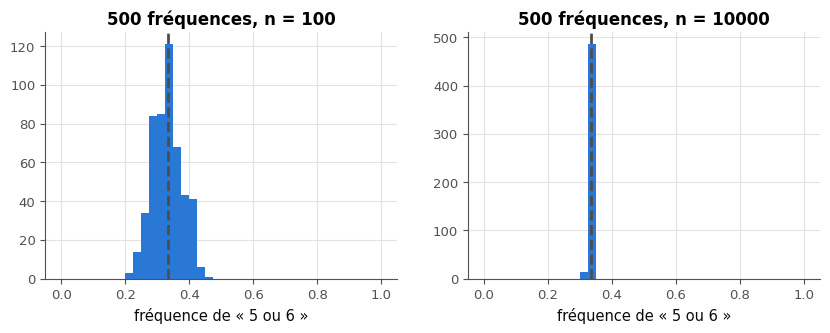

In [34]:
rng = np.random.default_rng(81)
far, kept = [], {}
for n in sizes:
    freqs = (rng.integers(1, 7, size=(500, n)) >= 5).mean(axis=1)
    far.append(float(np.mean(np.abs(freqs - 1 / 3) > 0.05)))
    kept[n] = freqs
mean_10000 = float(kept[10000].mean())
answer_R8_21c = 0
print("a)", far, " b)", round(mean_10000, 4))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for ax, n in zip(axes, (100, 10000)):
    ax.hist(kept[n], bins=40, range=(0, 1))
    ax.axvline(1 / 3, color="0.3", linestyle="--")
    ax.set_title(f"500 fréquences, n = {n}")
    ax.set_xlabel("fréquence de « 5 ou 6 »")
plt.show()

In [35]:
import numpy as np
rng = np.random.default_rng(81)
proportions, means = [], []
for n in [10, 100, 1000, 10000]:
    freqs = (rng.integers(1, 7, size=(500, n)) >= 5).mean(axis=1)
    proportions.append(float(np.mean(np.abs(freqs - 1 / 3) > 0.05)))
    means.append(float(freqs.mean()))
renewed = []                                    # the classic slip: a generator created again for each n
for n in [10, 100, 1000, 10000]:
    freqs = (np.random.default_rng(81).integers(1, 7, size=(500, n)) >= 5).mean(axis=1)
    renewed.append(float(np.mean(np.abs(freqs - 1 / 3) > 0.05)))
wbm.record("R8.21a", proportions, decimals=3,
           mistakes={"un seul générateur, créé avant la boucle avec la graine 81 : recréé à chaque n, il repart du "
                     "même point": renewed})
wbm.record("R8.21b", means[-1], decimals=4)
wbm.record("R8.21c", 0.0, decimals=2, mistakes={"c'est la proportion des séries qui s'écartent de plus de 0,05 : "
                                                "regarde comment elle évolue quand n grandit": {0.05, 0.33}})

WBM_ANSWER {"decimals": 3, "element_coarse": [["4b52f8987da9119b07dfbdc3b9a6045c030cb4d57e6d60e897f2f4d2aca0089a"], ["a669aced58f85dfc60834c9e0f794cc2d75d700779919771de5d8a686b9ee490"], ["0e706af851b8772223a6af72a850ce01a4f88790ec1d7de2743933b6e1d41192"], ["78e4e1a0ac1de72425efb9ce37b60ff423cc13391d0906617ad142ed2c5af513"]], "element_coarse_any": [["247219846860cf98229bb3a53dbce143831859d487cc486825e4de5bea7891e9", "4b5ba697e8c1eff5b2fd3d8125019a56bf1b19184d7bef8e782ca4f8ad79f7c2"], ["a54684b786801dd91af2a941e0d6205d45429077b73390bca1f4dbdbfc187af5"], [], []], "element_hashes": ["a0e6c0fea3809e527839e303890b0c45a163533c0f534e54ba9cfb8dc61acf53", "a65600d9c0495deb86f3c874672075c353e8588619bfeda6a4b01ced9dc7e94b", "7c3c5f835e503dfc86822481dabc55d1d0e255db6ee28be6097684503d1d7e1b", "b684abe444b11db897e710fe8ed8f29644fe831646c70735fcf239faeea1c755"], "hash": "1d403907ec5e9cc18b148075b58f51b069cfd3c2fda26dd71c85ba652e25621a", "id": "R8.21a", "kind": "array", "mistakes": {"7e11e3965516f321bb

💡 Les proportions valent 0,772, 0,28, 0,002 et 0 : avec 10 lancers, une série sur quatre seulement reste à moins de 0,05 de $\frac{1}{3}$ ; avec 10 000, toutes. La loi des grands nombres dit exactement cela : la probabilité que la fréquence s'écarte de la probabilité de plus d'un écart donné tend vers 0. Elle ne dit pas que la fréquence **égale** la probabilité, ni à partir de quel $n$ on est tranquille : pour un écart de 0,01, il faut beaucoup plus de lancers (l'écart typique est d'environ 0,005 pour $n = 10\,000$).

### Ex R8.22 — Le diagramme en bâtons d'une loi 🎨 ★ ⏱️ 10 min
**Objectif :** tracer la loi d'une variable aléatoire discrète et y placer son espérance.  
**Prérequis :** fiche §6 et §7 ; R0 (matplotlib) · **Parcours :** C

Complète `plot_law(ax, values, probabilities)`, qui dessine dans l'axe `ax` qu'elle reçoit :
- un bâton par valeur, centré sur la valeur, de hauteur sa probabilité (`ax.bar(values, probabilities, width=0.2)`) ;
- une droite verticale en pointillés à l'espérance, **calculée dans la fonction** à partir de `values` et `probabilities` (`ax.axvline`) ;
- un titre, et le nom des deux axes.

La cellule suivante trace la loi du nombre de piles en quatre lancers d'une pièce (`piles_values`, `piles_probs`, fournies), puis une autre la vérifie.

Dans ta copie : où se trouve l'espérance, et pourquoi pouvait-on la prévoir sans calcul ? Pourquoi la loi n'est-elle pas « plate », alors que les 16 suites de quatre lancers sont équiprobables ?

In [36]:
piles_values = [0, 1, 2, 3, 4]                       # number of piles in four coin flips
piles_probs = [1 / 16, 4 / 16, 6 / 16, 4 / 16, 1 / 16]

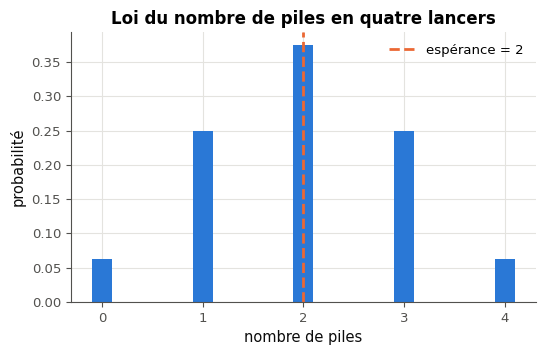

In [37]:
def plot_law(ax, values, probabilities):
    """Draw the law (one bar per value) in ax, with a dashed vertical line at the expectation."""
    mean = sum(v * p for v, p in zip(values, probabilities))
    ax.bar(values, probabilities, width=0.2)
    ax.axvline(mean, color="C1", linestyle="--", label=f"espérance = {mean:g}")
    ax.set_title("Loi du nombre de piles en quatre lancers")
    ax.set_xlabel("nombre de piles")
    ax.set_ylabel("probabilité")
    ax.legend()


fig, ax = plt.subplots(figsize=(6, 3.5))
plot_law(ax, piles_values, piles_probs)
plt.show()

**Vérifications automatiques** (la figure elle-même se juge à l'œil).

In [38]:
with checked("R8.22 vérifications"):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    try:
        created = drawn(plot_law, ax, piles_values, piles_probs)
    finally:
        plt.close(fig)                                     # only the checks below are shown here
    problems = []
    if created:
        problems.append("ta fonction ouvre sa propre figure : dessine dans l'axe reçu (ax.bar, …)")
    else:
        heights = sorted((round(float(p.get_x() + p.get_width() / 2), 6), round(float(p.get_height()), 6))
                         for p in ax.patches)
        expected = sorted((float(v), round(float(p), 6)) for v, p in zip(piles_values, piles_probs))
        if heights != expected:
            problems.append("un bâton par valeur, centré sur la valeur, de hauteur sa probabilité (ax.bar)")
        mean = sum(v * p for v, p in zip(piles_values, piles_probs))
        verticals = [l for l in ax.lines if len(set(np.round(np.asarray(l.get_xdata(), dtype=float), 6))) == 1]
        if not any(np.isclose(float(np.asarray(l.get_xdata(), dtype=float)[0]), mean) for l in verticals):
            problems.append("une droite verticale à l'espérance (ax.axvline), calculée dans la fonction")
        if not ax.get_title() or not ax.get_xlabel() or not ax.get_ylabel():
            problems.append("un titre et le nom des deux axes (ax.set_title, ax.set_xlabel, ax.set_ylabel)")
    if problems:
        print("❌ Ex R8.22 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R8.22 : les bâtons, l'espérance, le titre et les axes.")

✅ Ex R8.22 : les bâtons, l'espérance, le titre et les axes.


💡 La loi est symétrique autour de 2 : l'espérance vaut 2, au centre. Elle n'est pas plate parce que les valeurs de la variable regroupent des nombres différents de suites équiprobables : 1, 4, 6, 4, 1, les coefficients binomiaux $\binom{4}{k}$ (§3).

## Partie C · Raisonnements faux et reproductibilité

Fiche §2, §5 et §8. Trois raisonnements faux à trouver, puis une expérience aléatoire reproductible.

### Ex R8.23 — Chasse à l'erreur : trois raisonnements de probabilités faux 🐛 ★★ ⏱️ 20 min
**Objectif :** repérer des raisonnements faux (réunion, équiprobabilité, indépendance), puis calculer les bonnes probabilités.  
**Prérequis :** fiche §2 et §5 · **Parcours :** C, E

Voici cinq raisonnements. Trois sont faux. **Sans calculer d'abord**, trouve-les.

- **(A)** « On lance deux fois un dé à 4 faces. La probabilité d'obtenir au moins un 4 est $\frac{1}{4} + \frac{1}{4} = \frac{1}{2}$. »
- **(B)** « On lance deux pièces. On obtient 0, 1 ou 2 piles : trois cas, donc $P(\text{exactement un pile}) = \frac{1}{3}$. »
- **(C)** « $P(A) = 0{,}5$, $P(B) = 0{,}4$, et $A$ et $B$ sont indépendants, donc $P(A \cap B) = 0{,}5 \times 0{,}4 = 0{,}2$. »
- **(D)** « Une roue a 10 secteurs égaux, dont 3 rouges et 2 verts. Un secteur n'est jamais rouge et vert à la fois, donc $P(\text{rouge ou vert}) = \frac{3}{10} + \frac{2}{10} = \frac{1}{2}$. »
- **(E)** « $A$ et $B$ sont incompatibles, avec $P(A) = 0{,}3$ et $P(B) = 0{,}5$. Ils sont donc indépendants, et $P(A \cap B) = 0{,}3 \times 0{,}5 = 0{,}15$. »

Questions :
- a) les lettres des raisonnements faux, dans l'ordre alphabétique (un texte) ;
- b) les **bonnes** valeurs des probabilités que calculent les trois raisonnements faux, dans l'ordre alphabétique de leurs lettres (une liste, 4 décimales).

Dans ta copie : pour chaque raisonnement faux, quelle règle a été oubliée ? Lequel des deux raisonnements justes pouvait sembler faux, et pourquoi ne l'est-il pas ?

In [39]:
answer_R8_23a = "ABE"
answer_R8_23b = [1 - (3 / 4) ** 2, 2 / 4, 0.0]
print(answer_R8_23a, answer_R8_23b)

ABE [0.4375, 0.5, 0.0]


In [40]:
wbm.record("R8.23a", "ABE",
           mistakes={"il manque une ligne fautive : deux événements qui peuvent se réaliser ensemble ne s'additionnent pas : passe par le contraire": "BE",
                     "il manque une ligne fautive : les trois nombres de piles ne sont pas équiprobables : distingue les deux pièces": "AE",
                     "il manque une ligne fautive : incompatibles n'est pas indépendants : l'un empêche l'autre": "AB",
                     "une ligne de trop : la ligne (C) est correcte ; relis ce qu'elle fait": "ABCE",
                     "une ligne de trop : la ligne (D) est correcte ; relis ce qu'elle fait": "ABDE",
                     "la ligne (C) est correcte, et il manque une ligne fautive : deux événements qui peuvent se réaliser ensemble ne s'additionnent pas : passe par le contraire": "BCE",
                     "la ligne (D) est correcte, et il manque une ligne fautive : deux événements qui peuvent se réaliser ensemble ne s'additionnent pas : passe par le contraire": "BDE",
                     "la ligne (C) est correcte, et il manque une ligne fautive : les trois nombres de piles ne sont pas équiprobables : distingue les deux pièces": "ACE",
                     "la ligne (D) est correcte, et il manque une ligne fautive : les trois nombres de piles ne sont pas équiprobables : distingue les deux pièces": "ADE",
                     "la ligne (C) est correcte, et il manque une ligne fautive : incompatibles n'est pas indépendants : l'un empêche l'autre": "ABC",
                     "la ligne (D) est correcte, et il manque une ligne fautive : incompatibles n'est pas indépendants : l'un empêche l'autre": "ABD",
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "B", "E"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"C", "D", "AC", "AD", "BC", "BD", "CD", "CE", "DE", "ACD", "BCD", "CDE", "ABCD", "ACDE", "BCDE"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE"}})
wbm.record("R8.23b", [7 / 16, 0.5, 0.0], decimals=4,
           mistakes={"ce sont les valeurs des raisonnements faux : calcule les bonnes": [0.5, 1 / 3, 0.15],
                     "(A) : « au moins un 4 » est le contraire de « aucun 4 »": [0.5, 0.5, 0.0],
                     "(E) : deux événements incompatibles ne se réalisent jamais ensemble": [7 / 16, 0.5, 0.15]})

WBM_ANSWER {"hash": "25a0066f73c3be9fa6c02d3146e329e9dff3fba4a3f583be7c3d098b787a6b23", "id": "R8.23a", "kind": "str", "mistakes": {"03144b01c21ec91b727d1d43b3fcf81e0ab790f7fcc54fda55f7584a45bd8552": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0754f0f3d343e8a9c857f96a517494c5732ddc7b44f7c5d0d424a9ccf8bbcb90": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "08de189e48837b2b9022e2bfd111cd220034bbeb2b629a69abb4493150c0f878": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "09a70f542b8777360bb319cf06fbef6e89b23a3a2356f5bdb4d89a1e8e8521ac": "il manque une ligne fautive : deux événements qui peuvent se réaliser ensemble ne s'additionnent pas : passe par le contraire", "0ab76ce34dd70330aaa808d6a364a387d0de81be740297ed7f6255724a019522": "la ligne (D) est correcte, et il

💡 (A) « Au moins un 4 » est le contraire de « aucun 4 » : $1 - \left(\frac{3}{4}\right)^2 = \frac{7}{16}$ (les deux « 4 » peuvent arriver ensemble, d'où l'erreur de l'addition). (B) Deux pièces font 4 suites équiprobables, dont 2 avec un seul pile : $\frac{1}{2}$. (E) Incompatibles : $P(A \cap B) = 0$. (D) est juste : rouge et vert sont incompatibles, on additionne. (C) aussi : c'est la définition de l'indépendance.

### Ex R8.24 — Reproductibilité : générateur aléatoire et graine 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire une expérience aléatoire reproductible, et reconnaître le bug du générateur recréé à chaque tour.  
**Prérequis :** fiche §8 ; workbookIA 0A §100.8.7 · **Parcours :** C, E

Dans workbookIA, chaque expérience fixe sa graine, pour que tes résultats soient ceux du corrigé. La fonction `measure(rng)` (fournie) simule un score bruité : l'accuracy d'un modèle mesurée sur 200 exemples de test tirés avec le générateur `rng`.

1. Écris `run_experiments(n_runs, seed)`, qui renvoie la liste de `n_runs` mesures, avec **un seul** générateur `np.random.default_rng(seed)`, créé avant la boucle.
2. La cellule de vérification contrôle que la même graine redonne les mêmes mesures, que les mesures diffèrent entre elles, et qu'une autre graine donne d'autres mesures ; puis elle affiche le résultat de `buggy_runs(5, 42)` (fournie).

Dans ta copie : que remarques-tu sur les mesures de `buggy_runs` ? Quelle ligne cause ce bug, et pourquoi ? Que mesure l'écart entre tes 5 mesures, et pourquoi ne faut-il pas comparer deux modèles sur une seule mesure ?

In [41]:
def measure(rng):
    """A noisy score: the accuracy of a model measured on 200 test examples drawn with rng."""
    return float((rng.random(200) < 0.85).mean())


def buggy_runs(n_runs, seed):
    """n_runs measures... with a classic bug."""
    results = []
    for _ in range(n_runs):
        rng = np.random.default_rng(seed)
        results.append(measure(rng))
    return results

In [42]:
def run_experiments(n_runs, seed):
    """n_runs measures, with ONE generator default_rng(seed) created before the loop."""
    rng = np.random.default_rng(seed)
    return [measure(rng) for _ in range(n_runs)]


print("run_experiments(5, 42) :", run_experiments(5, 42))
print("buggy_runs(5, 42)      :", buggy_runs(5, 42))

run_experiments(5, 42) : [0.875, 0.86, 0.865, 0.84, 0.805]
buggy_runs(5, 42)      : [0.875, 0.875, 0.875, 0.875, 0.875]


💡 `buggy_runs` recrée le générateur avec la même graine à chaque tour : il repart du même point, et les 5 mesures sont identiques. Ce n'est pas « plus reproductible », c'est une seule mesure répétée. Les 5 mesures de `run_experiments` varient de quelques points : c'est la fluctuation d'un score mesuré sur 200 exemples ; une différence de cet ordre entre deux modèles peut venir du seul hasard.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Calcules-tu une probabilité par équiprobabilité, par le contraire ou avec un arbre ?
2. Sais-tu choisir entre $n^k$, les arrangements, $n!$ et $\binom{n}{k}$, et tester une indépendance ?
3. Calcules-tu l'espérance et la variance d'une loi, et sais-tu dire ce qu'affirme la loi des grands nombres ?

**La suite** : R9, *Géométrie du plan, vecteurs et trigonométrie*. Dans workbookIA, continue le chapitre 0A au rythme de ton tableau de bord.